In [1]:
import gymnasium as gym
import torch
from torch import nn

import numpy as np

import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython import display
from IPython.display import HTML
%matplotlib inline

In [2]:
# Create our training environment - a cart with a pole that needs balancing
env = gym.make("CartPole-v1", render_mode="rgb_array")

# Reset environment to start a new episode
observation, info = env.reset()
# observation: what the agent can "see" - cart position, velocity, pole angle, etc.
# info: extra debugging information (usually not needed for basic learning)

print(f"Starting observation: {observation}")
# Example output: [ 0.01234567 -0.00987654  0.02345678  0.01456789]
# [cart_position, cart_velocity, pole_angle, pole_angular_velocity]



Starting observation: [ 0.03082134 -0.001763   -0.02385093 -0.03597814]


## A Vanilla Learner

We implement an agent that given a current state returns an action. The agent models actions with an MLP. The net outputs a probability for each action and the agent samples the action to take from the probability distribution predicted.

In [3]:
class Agent(nn.Module):
    def __init__(self, state_dim, action_dim, hidden_dim=8, temp=1.0):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, action_dim)
        )
        self.temp = temp

    def act(self, observation, temp=None):
        if temp is None:
            temp = self.temp
        preds = self.net(torch.tensor(observation, dtype=torch.float32))
        if temp <= 0.0:
            # If temp is 0, we always take the best action
            return torch.argmax(preds).item()
        preds = preds / temp
        probabilities = torch.softmax(preds, dim=0)
        # Sample an action based on the probabilities
        action = torch.multinomial(probabilities, 1).item()
        return action

First we implement the code to let the agent play an episode:

In [4]:
def play_episode(env, agent, render=False):
    observation, info = env.reset()
    episode_over = False
    total_reward = 0

    X = []
    actions = []
    frames = []

    while not episode_over:
        action = agent.act(observation)
        X.append(observation)
        actions.append(action)
        if render:
            frames.append(env.render())

        observation, reward, terminated, truncated, info = env.step(action)
        total_reward += reward
        episode_over = terminated or truncated

    if render and frames:
        fig, ax = plt.subplots()
        ax.axis('off')
        img = ax.imshow(frames[0])
        def update(frame):
            img.set_data(frame)
            return [img]
        ani = FuncAnimation(fig, update, frames=frames, interval=50, blit=True)
        display.display(HTML(ani.to_jshtml()))
        plt.close(fig)

    return total_reward, np.stack(X), np.stack(actions)

In [8]:
agent = Agent(4, env.action_space.n)
total_reward, X, actions = play_episode(env, agent, render=True)

### Vanilla Training

The Agent will learn via imitation learning from itself. The algorithm is as follows:

1. Let the agent play several episodes. Since the agent sample its actions there is some stochasticity and it will perform better in some episodes than in others.
2. Take the episode where the agent perform better. Recording at each step the observation that was feed into de agent and the action it took.
3. Compute scores from the observations of the best performing episode.
4. Maximize the likelihood of the scores predicted for the actions taken on the best performing episodes. 

In [ ]:
def train_step(agent, env, optimizer, n_episodes=10):
    assert n_episodes > 1

    with torch.no_grad():
        episodes = [play_episode(env, agent) for _ in range(n_episodes)]

    total_rewards, Xs, action_seqs = zip(*episodes)
    avg_reward = sum(total_rewards) / n_episodes
    max_reward = max(total_rewards)

    X = np.concat([x for x, r in zip(Xs, total_rewards) if r == max_reward])
    y = np.concat([a for a, r in zip(action_seqs, total_rewards) if r == max_reward])

    X_tensor = torch.tensor(X, dtype=torch.float32)
    y_tensor = torch.tensor(y, dtype=torch.int64)

    optimizer.zero_grad()
    probs = torch.softmax(agent.net(X_tensor), dim=-1)
    loss = -torch.log(probs[torch.arange(len(y_tensor)), y_tensor]).mean()
    loss.backward()
    optimizer.step()

    return loss.item(), avg_reward


In [14]:
def train_agent(agent, optimizer, env, n_iterations=1000, n_episodes=10):
    losses = []
    avg_rewards = []
    for i in range(n_iterations):
        curr_loss, avg_reward = train_step(agent=agent, env=env, optimizer=optimizer, n_episodes=n_episodes)
        losses.append(curr_loss)
        avg_rewards.append(avg_reward)
        if i%10 == 0:
            print(f'\r[{100*(i+1)/n_iterations:.0f}%] Iteration {i+1}/{n_iterations}  loss: {curr_loss:.4f} average reward: {avg_reward:.4f}', end='', flush=True)

    return losses, avg_rewards

In [15]:
agent = Agent(4, env.action_space.n)
optimizer = torch.optim.Adam(agent.parameters(), lr=1e-3)


losses, avg_rewards = train_agent(agent, optimizer=optimizer, env=env, n_iterations=3000, n_episodes=20)

[100%] Iteration 2991/3000  loss: 0.5531 average reward: 500.0000

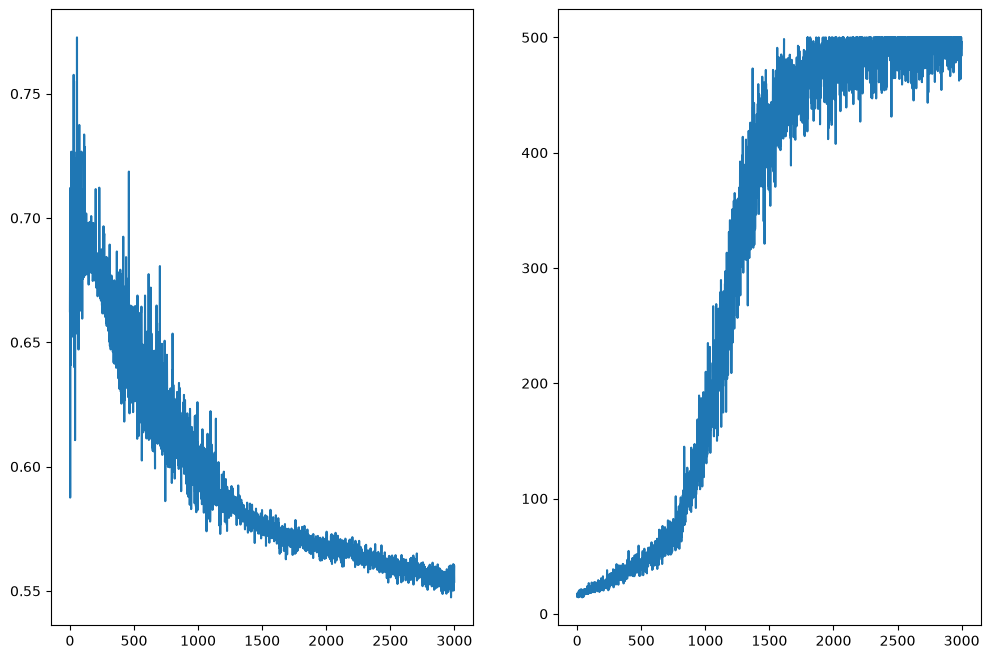

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 8))

axes[0].plot(losses, label=f"Training loss")

axes[1].plot(avg_rewards, label=f'Avg. Reward during training')

plt.show()

In [17]:
total_reward, X, actions = play_episode(env, agent, render=True)